# Regularization with PyTorch built-ins

The same football problem and the same 3-layer network as in `regularization.ipynb`, but using the ready-made tools:

| Method | From scratch (`model.py`) | PyTorch |
|---|---|---|
| L2 | `dW += lambd / m * W` | `torch.optim.SGD(..., weight_decay=lambd / m)` |
| Dropout | mask `D`, activations divided by `keep_prob` | `nn.Dropout(p=1 - keep_prob)` |
| Train vs prediction mode | `keep_prob=1` at prediction | `model.train()` / `model.eval()` |

Data split and hyperparameters are taken from the NumPy notebook (lambda = 0.3, keep_prob = 0.8, chosen on its validation half), no new tuning here.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!git clone -b feat/regularization-l2-dropout https://github.com/nyawmolny/deep-learning-fundamentals/

Cloning into 'deep-learning-fundamentals'...
remote: Enumerating objects: 293, done.
remote: Counting objects: 100% (293/293), done.
remote: Compressing objects: 100% (211/211), done.
remote: Total 293 (delta 65), reused 267 (delta 47), pack-reused 0 (from 0)
Receiving objects: 100% (293/293), 3.75 MiB | 34.25 MiB/s, done.
Resolving deltas: 100% (65/65), done.


In [3]:
%cd deep-learning-fundamentals/02-regularization-and-optimization/regularization/

/content/deep-learning-fundamentals/02-regularization-and-optimization/regularization


In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from data import load_football, plot_decision_boundary
from model import RegularizedNetwork, initialize_parameters
from torch import nn

SEEDS = range(5)
DIMS = [2, 40, 20, 1]
LR, EPOCHS = 0.3, 15000
LAMBD, KEEP_PROB = 0.3, 0.8

In [5]:
LOCAL_DATA = Path("data")
DRIVE_DATA = Path("/content/drive/MyDrive/data/02-regularization-and-optimization/regularization/data/")

DATA_DIR = DRIVE_DATA if DRIVE_DATA.exists() else LOCAL_DATA
print("Using data from:", DATA_DIR.resolve())

DRIVE_ASSETS = Path("/content/drive/MyDrive/data/02-regularization-and-optimization/regularization/assets")
LOCAL_ASSETS = Path("./assets")

ASSETS = DRIVE_ASSETS if Path("/content/drive/MyDrive").exists() else LOCAL_ASSETS
ASSETS.mkdir(parents=True, exist_ok=True)
print("Saving assets to:", ASSETS.resolve())

Using data from: /content/drive/MyDrive/data/02-regularization-and-optimization/regularization/data
Saving assets to: /content/drive/MyDrive/data/02-regularization-and-optimization/regularization/assets


## 1. Data and model builder

In [6]:
X_tr, Y_tr = load_football(str(DATA_DIR / "train.csv"))
X_hold, Y_hold = load_football(str(DATA_DIR / "val.csv"))

def split_val_test(Y, seed=0):
    # stratified 50/50 split of the held-out points into validation and test indices
    rng = np.random.default_rng(seed)
    val, test = [], []
    for c in (0.0, 1.0):
        idx = rng.permutation(np.where(Y[0] == c)[0])
        half = len(idx) // 2
        val += list(idx[:half])
        test += list(idx[half:])
    return np.array(sorted(val)), np.array(sorted(test))


va_idx, te_idx = split_val_test(Y_hold)
X_va, Y_va = X_hold[:, va_idx], Y_hold[:, va_idx]
X_te, Y_te = X_hold[:, te_idx], Y_hold[:, te_idx]
M = Y_tr.shape[1]


def to_t(X, Y, dtype=torch.float32):
    # PyTorch convention: examples in rows
    return torch.as_tensor(X.T, dtype=dtype), torch.as_tensor(Y.T, dtype=dtype)


X_tr_t, y_tr = to_t(X_tr, Y_tr)
X_te_t, y_te = to_t(X_te, Y_te)


def make_model(dims, p_drop=0.0):
    layers = []
    for i in range(1, len(dims)):
        layers.append(nn.Linear(dims[i - 1], dims[i]))
        if i < len(dims) - 1:
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
    model = nn.Sequential(*layers)
    for layer in model:
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    return model


def train(model, X, y, lr, epochs, weight_decay=0.0):
    # L2 only on weights, not on biases (same as the from-scratch version)
    weights = [p for n, p in model.named_parameters() if n.endswith("weight")]
    biases = [p for n, p in model.named_parameters() if n.endswith("bias")]
    optimizer = torch.optim.SGD(
        [{"params": weights, "weight_decay": weight_decay}, {"params": biases, "weight_decay": 0.0}], lr=lr
    )
    criterion = nn.BCEWithLogitsLoss()
    model.train()
    for _ in range(epochs):
        optimizer.zero_grad()
        criterion(model(X), y).backward()
        optimizer.step()


@torch.no_grad()
def accuracy(model, X, y):
    model.eval()
    return ((torch.sigmoid(model(X)) > 0.5).to(y.dtype) == y).float().mean().item()

## 2. `weight_decay` is our L2

For plain SGD, `weight_decay=w` adds `w * W` to the gradient. Our L2 adds `lambd / m * W`, so
`weight_decay = lambd / m`. Check: same initial weights, same data, no dropout, float64; the weights must coincide.

In [9]:
lambd, steps = 0.7, 300

np_net = RegularizedNetwork(DIMS, LR, steps, lambd=lambd, keep_prob=1.0, seed=0).fit(X_tr, Y_tr)

t_model = make_model(DIMS).double()
init = initialize_parameters(DIMS, seed=0)
with torch.no_grad():
    for l, layer in enumerate([m for m in t_model if isinstance(m, nn.Linear)], start=1):
        layer.weight.copy_(torch.as_tensor(init[f"W{l}"]))
        layer.bias.copy_(torch.as_tensor(init[f"b{l}"]).reshape(-1))
Xd, yd = to_t(X_tr, Y_tr, torch.float64)
train(t_model, Xd, yd, LR, steps, weight_decay=lambd / M)

diff = max(
    np.abs(layer.weight.detach().numpy() - np_net.params[f"W{l}"]).max()
    for l, layer in enumerate([m for m in t_model if isinstance(m, nn.Linear)], start=1)
)
print("max |weight difference| after", steps, "steps:", diff)

max |weight difference| after 300 steps: 4.440892098500626e-16


## 3. `nn.Dropout`: train mode vs eval mode

In [10]:
drop = nn.Sequential(nn.Dropout(p=0.5))
x = torch.ones(1, 10)

drop.train()
print("train mode, two calls:\n", drop(x), "\n", drop(x))
drop.eval()
print("eval mode, two calls:\n", drop(x), "\n", drop(x))

train mode, two calls:
 tensor([[2., 2., 0., 2., 2., 2., 0., 2., 2., 0.]]) 
 tensor([[2., 0., 0., 0., 0., 2., 2., 2., 2., 2.]])
eval mode, two calls:
 tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]]) 
 tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])


## 4. Results with built-in L2 and dropout (5 seeds)

In [22]:
def run(weight_decay=0.0, p_drop=0.0):
    rows = []
    models = []
    for s in SEEDS:
        torch.manual_seed(s)
        model = make_model(DIMS, p_drop)
        train(model, X_tr_t, y_tr, LR, EPOCHS, weight_decay)
        rows.append((accuracy(model, X_tr_t, y_tr), accuracy(model, X_te_t, y_te)))
        models.append(model)
    return np.array(rows), models


def pm(v):
    return f"{100 * v.mean():.1f} ± {100 * v.std():.1f}"


settings = {
    "no regularization": run(),
    f"L2 (weight_decay={LAMBD}/m)": run(weight_decay=LAMBD / M),
    f"dropout (p={1 - KEEP_PROB:.1f})": run(p_drop=1 - KEEP_PROB),
    "L2 + dropout": run(weight_decay=LAMBD / M, p_drop=1 - KEEP_PROB),
}
print(f"{'setting':<28} | train acc | test acc")
for name, (rows, _) in settings.items():
    print(f"{name:<28} | {pm(rows[:, 0])} | {pm(rows[:, 1])}")

setting                      | train acc | test acc
no regularization            | 99.9 ± 0.2 | 93.2 ± 0.7
L2 (weight_decay=0.3/m)      | 94.0 ± 0.6 | 95.6 ± 0.8
dropout (p=0.2)              | 95.6 ± 0.2 | 93.6 ± 1.0
L2 + dropout                 | 94.0 ± 0.6 | 92.8 ± 1.2


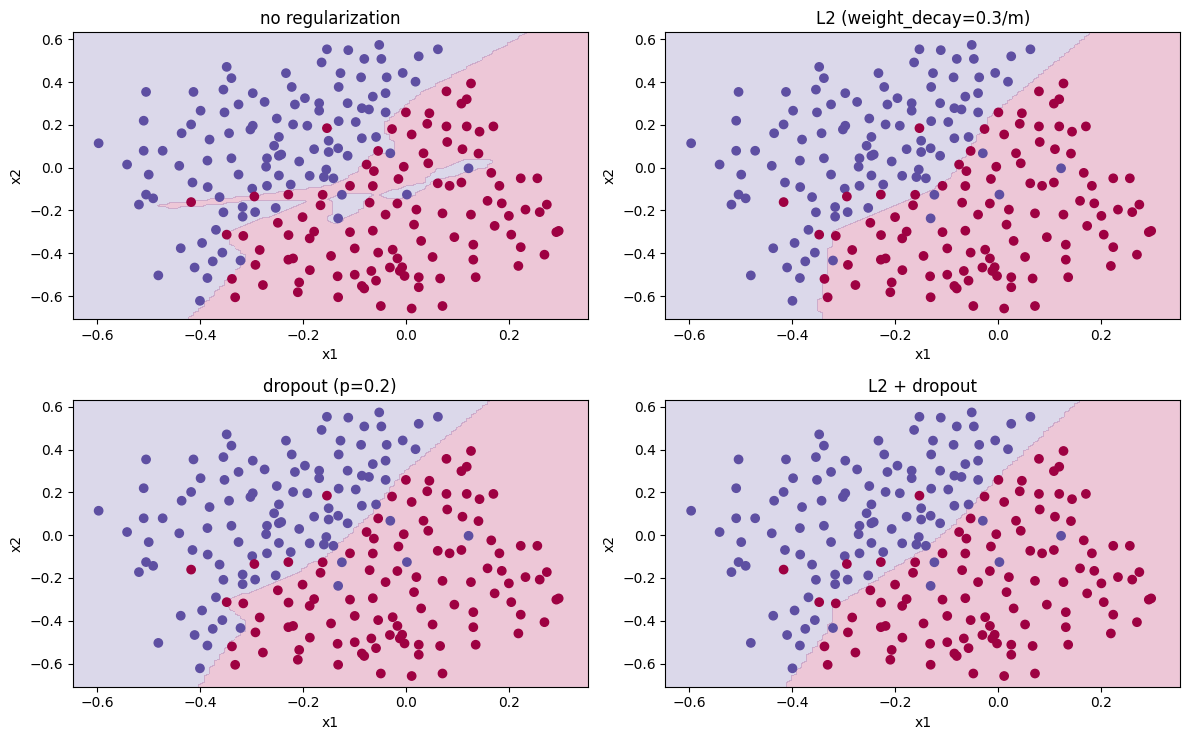

In [23]:
def predict_fn(model):
    def f(Z):    # Z: points (2, N) -> labels (1, N)
        model.eval()
        with torch.no_grad():
            return (torch.sigmoid(model(torch.as_tensor(Z.T, dtype=torch.float32))) > 0.5).numpy().T.astype(float)
    return f


fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for ax, (name, (_, models)) in zip(axes.ravel(), settings.items()):
    plot_decision_boundary(predict_fn(models[0]), X_tr, Y_tr, ax, name)
plt.tight_layout()
plt.savefig(ASSETS / "torch_decision_boundaries.png", dpi=150)
plt.show()

## 5. Notes

- **weight_decay vs from-scratch L2:** from identical initial weights (float64, no dropout), after 300 steps the maximum weight difference is 4.4e-16, i.e. machine precision. So `SGD(weight_decay=lambd / m)` is exactly our L2, which adds `lambd / m * W` to the gradient.

- **train() vs eval():** in train mode `nn.Dropout(p=0.5)` zeroes a random subset on every call (two calls gave different masks) and scales the kept values by 1 / (1 - p) = 2. In eval mode it is the identity (all ones, identical outputs). This is the same inverted dropout as in `model.py`, and it is why the model must be switched to `eval()` before predicting.

- **Agreement with the NumPy notebook:** same hyperparameters (lambda = 0.3, keep_prob = 0.8), different random initialization and masks, so the numbers are close but not identical. Train accuracy agrees within 0.6 pp in every setting and the pattern is the same: L2 and dropout lower train accuracy, and L2 + dropout is not better than L2 alone. Test accuracy is 0.6-2.2 pp higher in PyTorch. L2 beats no regularization on test in both notebooks (+2.0 NumPy, +2.4 PyTorch), but both use the same 100 test points, which is a small set, so the exact size of the gain is uncertain.